# IS 4487 Assignment 6: Data Cleaning with Airbnb Listings

In this assignment, you will:
- Load a raw Airbnb listings dataset
- Identify and resolve missing or inconsistent data
- Decide what data to drop, keep, or clean
- Save a clean dataset to use in Assignment 7

## Why This Matters

Data cleaning is one of the most important steps in any analysis — but it's often the least visible. Airbnb hosts, managers, and policy teams rely on clean data to make decisions. This assignment gives you experience cleaning raw data and justifying your choices so others can understand your process.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_06_data_cleaning.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

📌 The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.


## 1. Choose a City & Upload Your Dataset

📥 Follow these steps:

1. Go to: [https://insideairbnb.com/get-the-data/](https://insideairbnb.com/get-the-data/)
2. Choose a city you’re interested in.
3. Download the file named: **`listings.csv.gz`** under that city.
4. In your notebook:
   - Open the left sidebar
   - Click the folder icon 📁
   - Click the upload icon ⬆️ and choose your `listings.csv.gz` file
5. Use the file path `/content/listings.csv.gz` when loading your data.
6. Import standard libraries (`pandas`, `numpy`, `seaborn`, `matplotlib`)


In [1]:
# Import necessary libraries 🔧
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# Load your uploaded file (path "/content/listings.csv.gz") 🔧
airbnb = pd.read_csv("/content/listings.csv.gz")

## 2. Explore Missing Values

### Business framing:

Stakeholders don’t like surprises in the data. Missing values can break dashboards, confuse pricing models, or create blind spots for host managers.

### Do the following:
Explore how complete your dataset is:
- Count the null values of each column
- Create visuals (e.g. heatmaps, boxplots, bar charts, etc) to help show what columns are missing values
- Keep in mind which column(s) are missing too much data, you will delete these in the next step

neighborhood_overview                           490
host_since                                      490
host_response_time                              490
host_thumbnail_url                              490
host_acceptance_rate                            490
                                               ... 
availability_30                                   0
calculated_host_listings_count                    0
calculated_host_listings_count_entire_homes       0
calculated_host_listings_count_private_rooms      0
calculated_host_listings_count_shared_rooms       0
Length: 90, dtype: int64


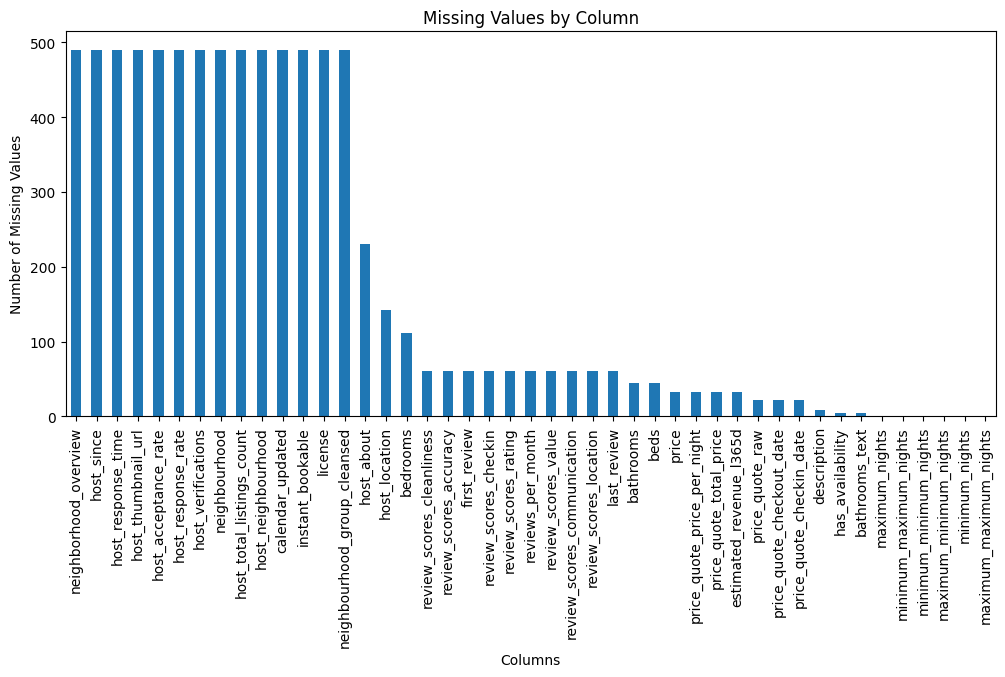

In [6]:
# Add code here 🔧
missing = airbnb.isnull().sum().sort_values(ascending=False)
print(missing)
missing[missing > 0].plot(kind="bar", figsize=(12, 5))

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.show()

### Reflection:
1. What are the top 3 columns with the most missing values?
2. Which ones are likely to create business issues?
3. Which could be safely ignored or dropped?

### ✍️ Your Response: 🔧
1. Neighbourhood_overview, host_since, host_response_time

2. Host_response_time, it is used to understand how responsive the hosts are to potential guest, these missing information could make the analysis less accurate

3. Neighbourhood_overview can be ignored, it is not a significant value for analysis


## 3. Drop Columns That Aren’t Useful

### Business framing:  

Not every column adds value. Analysts often remove columns that are too empty, irrelevant, or repetitive — especially when preparing data for others.

### Do the following:
Make a decision:

- Choose 2–4 columns to drop from your dataset
- Document your reasons for each one
- Confirm they're gone with `.head()` or `.info()`

In [7]:
# Add code here 🔧
airbnb = airbnb.drop(columns=[
    "neighborhood_overview",
    "host_thumbnail_url",
    "host_response_time"
])
airbnb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 490 entries, 0 to 489
Data columns (total 87 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            490 non-null    int64  
 1   listing_url                                   490 non-null    object 
 2   scrape_id                                     490 non-null    int64  
 3   last_scraped                                  490 non-null    object 
 4   source                                        490 non-null    object 
 5   name                                          490 non-null    object 
 6   description                                   481 non-null    object 
 7   picture_url                                   490 non-null    object 
 8   host_id                                       490 non-null    int64  
 9   host_url                                      490 non-null    obj

### Reflection:
1. Which columns did you drop?
2. Why were they not useful from a business perspective?
3. What could go wrong if you left them in?

### ✍️ Your Response: 🔧
1. I dropped neighbourhood_overview, host_thumbnail_url, host_response time

2. Neighbourhood_overview and host_thumbnail_url are not useful for analysis, but for host_response_time could be useful but there were too many missing values therefore it was not reliable

3. The analysis would be less accurate and will create problems when analyzing.



## 4. Fill or Fix Values in Key Columns

### Business framing:  

Let’s say your manager wants to see a map of listings with prices and review scores. If key fields are blank, the map won’t work. But not all missing values should be filled the same way.

### Do the following:
- Choose 2 columns with missing values
- Use a strategy to fill or flag those values
  - (e.g., median, “unknown”, forward-fill, or a placeholder)
- Explain what you did and why

In [8]:
# Your code for converting column data types 🔧
airbnb["price"] = airbnb["price"].replace(r"[\$,]", "", regex=True).astype(float)
airbnb["price"] = airbnb["price"].fillna(airbnb["price"].median())
airbnb["review_score_missing"] = airbnb["review_scores_rating"].isnull()
print(airbnb[["price", "review_scores_rating", "review_score_missing"]].head())

    price  review_scores_rating  review_score_missing
0   80.43                  3.56                 False
1  211.00                  4.75                 False
2   97.00                  4.52                 False
3  160.00                  4.73                 False
4   86.00                  4.58                 False


### Reflection:
1. What two columns did you clean?
2. What method did you use for each, and why?
3. What risks are there in how you filled the data?

### ✍️ Your Response: 🔧
1. Prie and review_score_rating

2. For price, I filled the missing values with the median as it has lesser impact by extreme prices, for review_score_rating, I created a missing value flag, missing review can emphasize no review.

3. For the review, since the actual reviews are not reviewed, the analysis may be limited, and for the price, the median would make different listings look similar than they are


## 5. Convert and Clean Data Types

### Business framing:  

Sometimes columns that look like numbers are actually stored as text — which breaks calculations and slows down analysis. Common examples are price columns with dollar signs or availability stored as strings.

### Do the following:
- Identify one column with the wrong data type
- Clean and convert it into a usable format (e.g., from string to number)
- Check your work by summarizing or plotting the cleaned column

In [9]:
# Clean or adjust your dataset 🔧
airbnb["last_scraped"] = pd.to_datetime(airbnb["last_scraped"])

print(airbnb["last_scraped"].dtype)
print(airbnb["last_scraped"].describe())

datetime64[ns]
count                              490
mean     2026-06-16 09:59:30.612244992
min                2026-06-16 00:00:00
25%                2026-06-16 00:00:00
50%                2026-06-16 00:00:00
75%                2026-06-16 00:00:00
max                2026-06-22 00:00:00
Name: last_scraped, dtype: object


### Reflection: :
1. What column did you fix?
2. What cleaning steps did you apply?
3. How does this help prepare the data for later use?

### ✍️ Your Response: 🔧
1. Last_scraped

2. I converted it into a datetime data type

3. This would make it easier to use for data base analysis. sorting, filtering.

## 6. Remove Duplicate Records

### Business framing:  

If a listing appears twice, it could inflate revenue estimates or confuse users. Airbnb needs each listing to be unique and accurate.

### Do the following:
- Check for rows that are exact duplicates
- If your data has an ID column and each ID is supposed to unique, then make sure there are no duplicate IDs
- Remove duplicates if found

In [13]:
# Add code here 🔧
print("Exact duplicate rows:", airbnb.duplicated().sum())
print("Duplicate IDs:", airbnb["id"].duplicated().sum())

Exact duplicate rows: 0
Duplicate IDs: 0


### Reflection:
1. Did you find duplicates?
2. How did you decide what to drop or keep?
3. Why are duplicates risky for Airbnb teams?

### ✍️ Your Response: 🔧 🔧
1. There is no duplicates

2. Both duplicate rows and duplicate ids are 0 so I kept them

3. It would make the reports and models less accurate

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 7**, where you'll perform data transformation techniques.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_6.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```





In [11]:
# export csv here 🔧
airbnb.to_csv("cleaned_airbnb_data_6.csv", index=False)

## 8. Final Reflection

You’ve just cleaned a real-world Airbnb dataset — the kind of work that happens every day in analyst and data science roles.

Before you move on to data transformation in Assignment 7, take a few moments to reflect on the decisions you made and what you learned.

### Reflection:
1. Which section of the assignment was the most challenging for you? What made it challenging? Was it the coding or the application of class concepts?
2. Look back at your assignment and discuss a time when you had to drop, fix, or keep a piece of data. Why was it necessary to drop, fix, or keep that specific piece of data? (e.x. dropping a column full of null values because it has no useful information)
3. What’s one way a business team (e.g., hosts, pricing analysts, app administrators) might benefit from the cleaned version of this data?
4. If you had more time, what would you explore or clean further?
5. How does this relate to your customized learning outcome you created in canvas?


Write your response clearly in full sentences. No more than a few sentences required per response.


### ✍️ Your Response: 🔧

1. __  Finding the missing values were the most difficult because I had hard time understanding the code and finding the missing values, or making a judgement whether to drop or keep the values.
2. __  The reason why I dropped host_response_time is because there were many missing values and it would affect my analysis.
3. __  The business team will benefit from the cleaned data as it is more consistent and easier to analyze
4. __  I think I would investigate more on the missing values and decide whether the missing values can be filled or dropped or kept.
5. __  This helped me to understand how to identify the missing values from a dataset which gave me a practice to make decision whether the data should be kept or dropped, allowing me to analyze and make decisions.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [12]:
!jupyter nbconvert --to html "assignment_06_data_cleaning.ipynb"

[NbConvertApp] Converting notebook assignment_06_data_cleaning.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 457547 bytes to assignment_06_data_cleaning.html
